In [1]:
!pip install -q gitpython

In [2]:
import os
from git import Repo

REPO_URL = "https://github.com/miguelgrinberg/flasky.git"   # <- swap this for a different repo
REPO_DIR = "/kaggle/working/demo_repo"

if not os.path.exists(REPO_DIR):
    Repo.clone_from(REPO_URL, REPO_DIR, depth=1)
    print(f"Cloned {REPO_URL} -> {REPO_DIR}")
else:
    print(f"{REPO_DIR} already exists, skipping clone")

Cloned https://github.com/miguelgrinberg/flasky.git -> /kaggle/working/demo_repo


In [3]:
import ast

def extract_chunks_from_file(filepath, repo_root):
    """Parse one Python file and pull out every function/class as a chunk."""
    with open(filepath, "r", encoding="utf-8", errors="ignore") as f:
        source = f.read()
    try:
        tree = ast.parse(source, filename=str(filepath))
    except SyntaxError:
        return []  # skip files that don't parse (rare, but happens)

    source_lines = source.splitlines()
    rel_path = os.path.relpath(filepath, repo_root)
    chunks = []

    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            start_line = node.lineno
            end_line = getattr(node, "end_lineno", start_line)
            chunks.append({
                "name": node.name,
                "type": "class" if isinstance(node, ast.ClassDef) else "function",
                "file": rel_path,
                "start_line": start_line,
                "end_line": end_line,
                "docstring": ast.get_docstring(node),
                "code": "\n".join(source_lines[start_line - 1:end_line]),
            })
    return chunks

# Note: ast.walk() visits nested nodes too, so a method inside a class shows up
# both inside its class's chunk AND as its own standalone chunk. That's intentional —
# it gives retrieval both a whole-class view and a precise single-method view to match against.

In [4]:
from pathlib import Path
from collections import defaultdict

SKIP_DIRS = {"venv", ".venv", "__pycache__", "tests", "test", ".git", "migrations"}
MIN_CODE_LINES = 3  # drop trivial one-liner chunks (e.g. `class Foo(Bar): pass`) that tend to
                     # embed near the center of vector space and get retrieved for almost everything

def chunk_repository(repo_root):
    repo_root = Path(repo_root)
    all_chunks = []
    for py_file in repo_root.rglob("*.py"):
        if any(part in SKIP_DIRS for part in py_file.parts):
            continue
        all_chunks.extend(extract_chunks_from_file(py_file, repo_root))
    return all_chunks

chunks = chunk_repository(REPO_DIR)
chunks = [c for c in chunks if len(c["code"].splitlines()) >= MIN_CODE_LINES]

# File-overview chunks: one synthetic chunk per file, summarizing what it contains.
# Thin files (email.py, decorators.py, __init__.py) have only 1-2 real chunks each,
# so they rarely win against big files like main/views.py on chunk count alone.
# An overview chunk gives every file at least one shot at matching a whole-module
# question ("how is email sent", "how is the app configured") even when no single
# function chunk is an obvious lexical match.
by_file = defaultdict(list)
for c in chunks:
    by_file[c["file"]].append(c)

overview_chunks = []
for file, file_chunks in by_file.items():
    names = [c["name"] for c in file_chunks]
    docs = [c["docstring"] for c in file_chunks if c["docstring"]]
    summary = f"File: {file}\nContains: {', '.join(names)}"
    if docs:
        summary += "\nDocumented as: " + " | ".join(docs)
    overview_chunks.append({
        "name": f"__file_overview__:{file}",
        "type": "file_overview",
        "file": file,
        "start_line": 1,
        "end_line": 1,
        "docstring": None,
        "code": summary,
    })

chunks = chunks + overview_chunks

functions = [c for c in chunks if c["type"] == "function"]
classes = [c for c in chunks if c["type"] == "class"]
overviews = [c for c in chunks if c["type"] == "file_overview"]
with_docs = [c for c in chunks if c["docstring"]]

print(f"Total chunks: {len(chunks)}")
print(f"  functions: {len(functions)}")
print(f"  classes:   {len(classes)}")
print(f"  file overviews: {len(overviews)}")
print(f"  with docstrings: {len(with_docs)} ({100 * len(with_docs) // max(len(chunks), 1)}%)")

Total chunks: 145
  functions: 102
  classes:   25
  file overviews: 18
  with docstrings: 3 (2%)


In [5]:
# Peek at one chunk to sanity-check the output
import json

sample = next((c for c in chunks if c["docstring"]), chunks[0])
print(json.dumps(sample, indent=2)[:800])

{
  "name": "test",
  "type": "function",
  "file": "flasky.py",
  "start_line": 34,
  "end_line": 56,
  "docstring": "Run the unit tests.",
  "code": "def test(coverage, test_names):\n    \"\"\"Run the unit tests.\"\"\"\n    if coverage and not os.environ.get('FLASK_COVERAGE'):\n        import subprocess\n        os.environ['FLASK_COVERAGE'] = '1'\n        sys.exit(subprocess.call(sys.argv))\n\n    import unittest\n    if test_names:\n        tests = unittest.TestLoader().loadTestsFromNames(test_names)\n    else:\n        tests = unittest.TestLoader().discover('tests')\n    unittest.TextTestRunner(verbosity=2).run(tests)\n    if COV:\n        COV.stop()\n        COV.save()\n        print('Coverage Summary:')\n        COV.report()\n        basedir = os.path.abspath(os.path.dirname(__file__


In [6]:
import json

OUTPUT_PATH = "/kaggle/working/code_chunks.json"

with open(OUTPUT_PATH, "w") as f:
    json.dump(chunks, f, indent=2)

print(f"Saved {len(chunks)} chunks to {OUTPUT_PATH}")

Saved 145 chunks to /kaggle/working/code_chunks.json


In [7]:
!pip install -q transformers datasets faiss-cpu networkx pandas matplotlib rapidfuzz accelerate sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 83.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 44.1 MB/s eta 0:00:0000:0100:01


In [8]:
import json, os
import numpy as np

CHUNKS_PATH = "/kaggle/working/code_chunks.json"   # from Week 1
REPO_DIR = "/kaggle/working/demo_repo"             # from Week 1

with open(CHUNKS_PATH) as f:
    chunks = json.load(f)

print(f"Loaded {len(chunks)} chunks from {CHUNKS_PATH}")

Loaded 145 chunks from /kaggle/working/code_chunks.json


In [9]:
from datasets import load_dataset

codesearchnet = load_dataset("code-search-net/code_search_net", "python")
print(codesearchnet)

# Small sample from the test split — enough for a precision@k check, cheap to embed
csn_eval = codesearchnet["test"].shuffle(seed=42).select(range(300))

README.md: 0.00B [00:00, ?B/s]

python/train-00000-of-00001.parquet:   0%|          | 0.00/522M [00:00<?, ?B/s]

python/test-00000-of-00001.parquet:   0%|          | 0.00/28.7M [00:00<?, ?B/s]

python/validation-00000-of-00001.parquet:   0%|          | 0.00/30.7M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/412178 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/22176 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/23107 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['repository_name', 'func_path_in_repository', 'func_name', 'whole_func_string', 'language', 'func_code_string', 'func_code_tokens', 'func_documentation_string', 'func_documentation_tokens', 'split_name', 'func_code_url'],
        num_rows: 412178
    })
    test: Dataset({
        features: ['repository_name', 'func_path_in_repository', 'func_name', 'whole_func_string', 'language', 'func_code_string', 'func_code_tokens', 'func_documentation_string', 'func_documentation_tokens', 'split_name', 'func_code_url'],
        num_rows: 22176
    })
    validation: Dataset({
        features: ['repository_name', 'func_path_in_repository', 'func_name', 'whole_func_string', 'language', 'func_code_string', 'func_code_tokens', 'func_documentation_string', 'func_documentation_tokens', 'split_name', 'func_code_url'],
        num_rows: 23107
    })
})


In [10]:
import torch
from sentence_transformers import SentenceTransformer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Swapped from raw "microsoft/codebert-base" to a model actually FINE-TUNED for
# code<->docstring retrieval. Raw CodeBERT is only pretrained with masked-language-
# modeling -- nothing in its training pushes semantically related code and text
# embeddings close together, which is exactly why the earlier precision@k scores
# (0.23-0.39) were weak. This model was fine-tuned specifically on CodeSearchNet
# for that retrieval objective, so embeddings of a docstring/question and the
# matching function land close together in vector space.
MODEL_NAME = "flax-sentence-embeddings/st-codesearch-distilroberta-base"

embed_model = SentenceTransformer(MODEL_NAME, device=DEVICE)

def embed_texts(texts, batch_size=32):
    """Sentence-Transformers embeddings for a list of strings -> (N, hidden_dim) numpy array."""
    return embed_model.encode(
        list(texts),
        batch_size=batch_size,
        show_progress_bar=False,
        convert_to_numpy=True,
        normalize_embeddings=True,   # unit-norm already, so inner product == cosine similarity
    )

def l2_normalize(vecs):
    """Kept for compatibility with the rest of the notebook (embed_texts output is
    already unit-norm, so this is a safe no-op pass-through)."""
    norms = np.linalg.norm(vecs, axis=1, keepdims=True)
    return vecs / np.clip(norms, 1e-8, None)

def chunk_embed_text(c):
    """What actually gets embedded for a chunk -- not just raw code.
    Adds the file path (as readable words, e.g. 'app auth views') and the
    docstring when present, so retrieval has more than syntax to match a
    natural-language question against. Module names like 'auth' vs 'main'
    carry real signal even when the function itself has no docstring."""
    path_words = c["file"].replace("/", " ").replace("_", " ").replace(".py", "")
    parts = [path_words, c["name"]]
    if c["docstring"]:
        parts.append(c["docstring"])
    parts.append(c["code"])
    return "\n".join(parts)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

...

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [11]:
chunk_texts = [chunk_embed_text(c) for c in chunks]
chunk_embeddings = l2_normalize(embed_texts(chunk_texts))
print("chunk_embeddings shape:", chunk_embeddings.shape)

chunk_embeddings shape: (145, 768)


In [12]:
import faiss

dim = chunk_embeddings.shape[1]
index = faiss.IndexFlatIP(dim)   # inner product on normalized vectors = cosine similarity
index.add(chunk_embeddings.astype("float32"))

faiss.write_index(index, "/kaggle/working/chunks.index")
with open("/kaggle/working/chunks_meta.json", "w") as f:
    json.dump(chunks, f)

print(f"Indexed {index.ntotal} chunks (dim={dim})")

Indexed 145 chunks (dim=768)


In [13]:
import ast
import networkx as nx
from pathlib import Path

known_functions = {c["name"] for c in chunks if c["type"] == "function"}

class CallVisitor(ast.NodeVisitor):
    def __init__(self):
        self.current_func = None
        self.edges = []

    def visit_FunctionDef(self, node):
        prev = self.current_func
        self.current_func = node.name
        self.generic_visit(node)
        self.current_func = prev

    visit_AsyncFunctionDef = visit_FunctionDef

    def visit_Call(self, node):
        if self.current_func:
            callee = None
            if isinstance(node.func, ast.Name):
                callee = node.func.id
            elif isinstance(node.func, ast.Attribute):
                callee = node.func.attr
            if callee and callee in known_functions:
                self.edges.append((self.current_func, callee))
        self.generic_visit(node)

def find_calls_in_file(filepath):
    with open(filepath, "r", encoding="utf-8", errors="ignore") as f:
        source = f.read()
    try:
        tree = ast.parse(source)
    except SyntaxError:
        return []
    visitor = CallVisitor()
    visitor.visit(tree)
    return visitor.edges

SKIP_DIRS = {"venv", ".venv", "__pycache__", "tests", "test", ".git", "migrations"}

call_graph = nx.DiGraph()
call_graph.add_nodes_from(known_functions)
for py_file in Path(REPO_DIR).rglob("*.py"):
    if any(part in SKIP_DIRS for part in py_file.parts):
        continue
    call_graph.add_edges_from(find_calls_in_file(py_file))

print(f"Call graph: {call_graph.number_of_nodes()} nodes, {call_graph.number_of_edges()} edges")
nx.write_gml(call_graph, "/kaggle/working/call_graph.gml")

Call graph: 84 nodes, 59 edges


In [14]:
from rapidfuzz import fuzz

chunk_by_name = {}
for c in chunks:
    chunk_by_name.setdefault(c["name"], []).append(c)

def keyword_score(query, chunk):
    """Fuzzy match against BOTH the function name and the file path --
    a question like "how does login work" should score app/auth/views.py
    highly even if no single function is literally named "login"."""
    name_score = fuzz.partial_ratio(query.lower(), chunk["name"].lower()) / 100.0
    path_score = fuzz.partial_ratio(query.lower(), chunk["file"].lower()) / 100.0
    return max(name_score, path_score)

def semantic_search(query, k=5):
    q_emb = l2_normalize(embed_texts([query])).astype("float32")
    scores, idxs = index.search(q_emb, k)   # higher score = more similar (cosine, via inner product)
    return [(chunks[i], float(s)) for i, s in zip(idxs[0], scores[0]) if i != -1]

def hybrid_retrieve(query, k=5, keyword_weight=0.55):
    pool = semantic_search(query, k=k * 6)   # wider pool -- we will collapse near-duplicates by file next
    scored = []
    for chunk, sem_score in pool:   # sem_score already in [-1, 1], higher = better
        kw_score = keyword_score(query, chunk)
        final_score = (1 - keyword_weight) * sem_score + keyword_weight * kw_score
        scored.append((chunk, final_score))
    scored.sort(key=lambda x: x[1], reverse=True)

    # Keep only the single best-scoring chunk PER FILE. Without this, a big file like
    # main/views.py can win 3-4 of the k slots with near-duplicate chunks, crowding out
    # genuinely better matches from smaller files -- this was the main driver of the
    # 50% ceiling (6 of 8 misses were main/views.py or main/forms.py stealing the slot).
    # One slot per file turns top-k into k distinct file guesses instead of fewer.
    best_per_file = {}
    for chunk, score in scored:
        if chunk["file"] not in best_per_file or score > best_per_file[chunk["file"]][1]:
            best_per_file[chunk["file"]] = (chunk, score)

    deduped = sorted(best_per_file.values(), key=lambda x: x[1], reverse=True)
    return deduped[:k]

def expand_with_call_graph(top_chunks, hops=1):
    expanded = {c["name"]: c for c, _ in top_chunks}
    frontier = list(expanded.keys())
    for _ in range(hops):
        next_frontier = []
        for name in frontier:
            if name in call_graph:
                for neighbor in call_graph.successors(name):
                    if neighbor not in expanded and neighbor in chunk_by_name:
                        expanded[neighbor] = chunk_by_name[neighbor][0]
                        next_frontier.append(neighbor)
        frontier = next_frontier
    return list(expanded.values())

## Grounded generation: hallucination prevention, confidence gating, citation validation

**Bug found in the previous run:** the proposed system scored 0% citation/supported-answer accuracy despite strong retrieval (Hit@1 93%). Debugging (see the debug cell below, which prints raw LLM output alongside the parsed result for several supported questions) traced this to the parser being too brittle: Qwen frequently wraps its structured output in light markdown (`**STATUS:** SUPPORTED`, backticked file names, a leading `### STATUS` heading, etc.), and the old regex required `STATUS:` to be followed immediately by whitespace then the literal word -- any markdown in between made it silently fall through to `INSUFFICIENT_EVIDENCE`. Since this happened on essentially every supported question, it explains the 100% abstention / 0% citation accuracy pattern: this was case **B** (parser failure), not the LLM failing to answer or the citation validator being wrong. The citation validator's strict-containment check (case C) was a secondary, smaller issue also fixed below.

Fix, in two parts:
1. **Source side** -- the prompt now explicitly asks for plain text with no markdown, reducing how often this happens in the first place.
2. **Receiving side** -- `normalize_llm_output` strips markdown noise before parsing, and the citation validator now uses interval overlap instead of exact containment, so a citation that lands anywhere inside the evidence we actually retrieved for that file is accepted, not just one matching one exact chunk boundary.

In [15]:
# ---------------------------------------------------------------------------
# Retrieval confidence threshold -- calibrated on a held-out DEV/calibration
# set, never on the 55-question final test set.
# ---------------------------------------------------------------------------
# Why this exists: retrieval always returns *something* for k results, even
# for a question that has nothing to do with this repo. The fused similarity
# score is our only signal for "does the retrieved code actually look like a
# match, or is this just the least-bad option in the index?" Below some
# score, treating the top hits as reliable evidence is exactly how a RAG
# system ends up confidently describing code that was never really
# retrieved.
#
# To pick that score without touching the final 55-question test set, we use
# a separate calibration set: questions clearly answerable from this repo,
# and questions that are clearly out of scope. We then try a grid of
# candidate thresholds and keep the one that best separates the two groups
# on THIS calibration set.
#
# FIX (item 1): the calibration set was previously only 6 questions -- far
# too few to trust a chosen threshold. It is now 18 (9 answerable / 9
# out-of-scope), covering a wider spread of the repo (auth, models, API,
# main blueprint, app factory) so the chosen threshold generalizes better.
# Every question below was written fresh for calibration and cross-checked
# against `test_questions` (cell below) to confirm there is zero overlap --
# calibration and the final test set stay completely separate, and the
# threshold is fixed *before* the final evaluation ever runs, so it is never
# tuned on the test set.
#
# HONEST LIMITATION: 18 calibration questions is still a small dev set -- a
# real deployment would want dozens to hundreds of labeled dev questions per
# repository/embedding model. Treat the value chosen below as a reasonable,
# documented starting point, not a proven-optimal constant.
DEV_CALIBRATION_QUESTIONS = [
    # -- answerable from this repo (relevant=True) --
    {"question": "How does the User model relate to Flask-Login?", "relevant": True},
    {"question": "What fields are defined on the Post model?", "relevant": True},
    {"question": "How is a confirmation token generated for a new user?", "relevant": True},
    {"question": "What does the Permission class define?", "relevant": True},
    {"question": "How does the API blueprint handle authentication errors?", "relevant": True},
    {"question": "What does the main blueprint's index view render?", "relevant": True},
    {"question": "How is Markdown converted to HTML for blog posts in this app?", "relevant": True},
    {"question": "What does the follow relationship between users look like in the models?", "relevant": True},
    {"question": "How does the app factory register its blueprints?", "relevant": True},
    # -- clearly out of scope for this repo (relevant=False) --
    {"question": "How does this app use Elasticsearch for search?", "relevant": False},
    {"question": "What does the app's GraphQL resolver for users do?", "relevant": False},
    {"question": "How is Celery used for background task processing here?", "relevant": False},
    {"question": "What OAuth provider does the app use for Facebook login?", "relevant": False},
    {"question": "How does the app implement WebSocket-based chat?", "relevant": False},
    {"question": "What message queue like RabbitMQ does this app rely on?", "relevant": False},
    {"question": "How does the app integrate with Sentry for error tracking?", "relevant": False},
    {"question": "What does the app's Docker Swarm deployment configuration look like?", "relevant": False},
    {"question": "How does the app send SMS notifications via Twilio?", "relevant": False},
]

def calibrate_threshold(candidates=None):
    if candidates is None:
        candidates = [round(x, 2) for x in [0.05 + 0.05 * i for i in range(12)]]
    scored = []
    for q in DEV_CALIBRATION_QUESTIONS:
        top = hybrid_retrieve(q["question"], k=5)
        top_score = top[0][1] if top else -1.0
        scored.append((top_score, q["relevant"]))

    best_t, best_acc = candidates[0], -1
    results = []
    for t in candidates:
        correct = sum(1 for score, relevant in scored if (score >= t) == relevant)
        acc = correct / len(scored)
        results.append((t, acc))
        # tie-break toward the HIGHER threshold: being slightly more willing
        # to abstain is safer for a hallucination-sensitive system than being
        # slightly more willing to guess.
        if acc >= best_acc:
            best_acc, best_t = acc, t
    return best_t, best_acc, results


RETRIEVAL_CONFIDENCE_THRESHOLD, _dev_acc, _dev_grid = calibrate_threshold()
print("Confidence-threshold calibration grid (score, dev-set accuracy):")
for t, acc in _dev_grid:
    marker = "  <-- chosen" if t == RETRIEVAL_CONFIDENCE_THRESHOLD else ""
    print(f"  {t:.2f}: {acc:.2f}{marker}")
print(f"\nUsing RETRIEVAL_CONFIDENCE_THRESHOLD = {RETRIEVAL_CONFIDENCE_THRESHOLD:.2f} "
      f"(dev-set accuracy {_dev_acc:.2f} on {len(DEV_CALIBRATION_QUESTIONS)} calibration "
      "questions, kept completely separate from the 55-question final test set below).")


Confidence-threshold calibration grid (score, dev-set accuracy):
  0.05: 0.50
  0.10: 0.50
  0.15: 0.50
  0.20: 0.50
  0.25: 0.50
  0.30: 0.50
  0.35: 0.50
  0.40: 0.50
  0.45: 0.56
  0.50: 0.67
  0.55: 0.78
  0.60: 0.78  <-- chosen

Using RETRIEVAL_CONFIDENCE_THRESHOLD = 0.60 (dev-set accuracy 0.78 on 18 calibration questions, kept completely separate from the 55-question final test set below).


In [16]:
import re

def build_grounded_prompt(query, context_chunks):
    """Prompt used by the PROPOSED system.

    FIX (post-run debugging round 2): the earlier fix (adding a one-shot
    example) helped a little, but the debug trace showed the model still
    reliably writes STATUS, then a full free-text ANSWER -- and then simply
    stops, never continuing on to write a CITATIONS section at all. This is
    a small-model habit: it treats the prose answer as "the response" and
    doesn't reliably resume a structured section afterwards, no matter how
    clearly the format is specified or demonstrated.

    The fix is to reorder the sections: STATUS, then the short, structured
    CITATIONS list, THEN the free-text ANSWER last. A small model is much
    more reliable at producing a short structured field early in its
    response than at remembering to append one after a long prose answer.
    Putting the part we can validate (citations) before the part that's
    naturally open-ended (the answer) means even if the model "runs out of
    steam" partway through the prose answer, the citations are already
    safely captured. No parser changes are needed for this: extract_citations
    already scans the entire response regardless of section order, and the
    ANSWER regex already captures everything from 'ANSWER:' to the end of
    the text when there is no later 'CITATIONS:' to stop at.
    """
    blocks = [
        f"# {c['file']}:{c['start_line']}-{c['end_line']} ({c['name']})\n{c['code']}"
        for c in context_chunks
    ]
    context_str = "\n\n".join(blocks) if blocks else "(no relevant code retrieved)"
    return (
        "You are a repository-grounded codebase assistant.\n"
        "Use ONLY the supplied repository evidence below. Do not use pretrained "
        "knowledge to fill missing information, and do not guess.\n"
        "Every repository-specific factual statement must be supported by the evidence.\n"
        "If the evidence does not support an answer, or the question is unrelated to this "
        "repository, abstain by returning STATUS: INSUFFICIENT_EVIDENCE.\n"
        "Never invent files, functions, classes, variables, APIs, or line numbers.\n\n"
        "Respond in PLAIN TEXT ONLY -- no markdown, no bold, no bullet points, no code fences -- "
        "in EXACTLY this format. You MUST always include all three sections IN THIS ORDER, even "
        "the CITATIONS section (write 'None' there if genuinely nothing applies). Write CITATIONS "
        "BEFORE the answer -- do not write the answer first:\n\n"
        "EXAMPLE OF THE REQUIRED FORMAT (copy the SHAPE and ORDER only, never this content):\n"
        "STATUS: SUPPORTED\n\n"
        "CITATIONS:\n"
        "app/models.py:120-135\n\n"
        "ANSWER:\n"
        "The Comment model stores a body, a timestamp, and a foreign key to the "
        "author who posted it.\n\n"
        "---\n\n"
        "Now answer the REAL question below, following that exact format and order:\n\n"
        "STATUS: SUPPORTED or INSUFFICIENT_EVIDENCE\n\n"
        "CITATIONS:\n"
        "<one per line as file.py:start-end, taken only from the file/line ranges shown "
        "below, or 'None'. Write this section BEFORE the answer.>\n\n"
        "ANSWER:\n"
        "<answer grounded only in the evidence below, or the sentence "
        "'The repository does not contain sufficient evidence to answer this question.'>\n\n"
        f"REPOSITORY EVIDENCE:\n{context_str}\n\n"
        f"QUESTION: {query}\n"
    )


def normalize_llm_output(text):
    """Strip markdown noise that does not change meaning but broke the old
    exact-match parser: bold/italic markers, backticks, code fences, and
    markdown headings/bullets in front of a keyword line. Deliberately does
    NOT touch single/double underscores, since real filenames in this repo
    (e.g. app/__init__.py) legitimately contain them."""
    text = re.sub(r"```[a-zA-Z]*\n?", "\n", text)
    text = text.replace("```", "")
    text = text.replace("**", "").replace("`", "")
    text = re.sub(r"^\s{0,3}#+\s*", "", text, flags=re.MULTILINE)
    text = re.sub(r"^\s{0,3}[-*•]\s+", "", text, flags=re.MULTILINE)
    text = re.sub(r"[ \t]+", " ", text)
    return text.strip()


_RANGE_RE = re.compile(
    r"([\w\-/\.]+\.py)\s*:?\s*(?:lines?\s*)?(\d+)\s*(?:[-–—]|to)\s*(\d+)",
    re.IGNORECASE,
)
_SINGLE_RE = re.compile(
    r"([\w\-/\.]+\.py)\s*:\s*(\d+)(?!\s*[-–—\d]|\s*to)",
    re.IGNORECASE,
)

def extract_citations(text):
    """Pull (file, start, end) triples out of free text. Handles both
    "file.py:10-30" and looser phrasings like "file.py lines 10 to 30" or a
    single line number "file.py:42" (treated as a 1-line range)."""
    citations, seen_spans = [], []
    for m in _RANGE_RE.finditer(text):
        citations.append((m.group(1), int(m.group(2)), int(m.group(3))))
        seen_spans.append(m.span())
    for m in _SINGLE_RE.finditer(text):
        if any(m.start() >= s0 and m.end() <= s1 for s0, s1 in seen_spans):
            continue
        line = int(m.group(2))
        citations.append((m.group(1), line, line))
    return citations


_STATUS_RE = re.compile(
    r"STATUS\s*:?\s*(SUPPORTED|INSUFFICIENT[_ ]EVIDENCE)",
    re.IGNORECASE,
)

def parse_structured_output(raw_text):
    """Pull STATUS / ANSWER / CITATIONS back out of the model's free-text
    response, tolerant of markdown, extra whitespace, and minor formatting
    drift (item 3 in the professor's feedback). Any response that still does
    not clearly state a STATUS after normalization is treated as insufficient
    evidence rather than guessed at -- a genuinely malformed response is
    itself a sign the model wasn't confidently grounded."""
    text = normalize_llm_output(raw_text)

    status_match = _STATUS_RE.search(text)
    if status_match:
        status = status_match.group(1).upper().replace(" ", "_")
    else:
        status = "INSUFFICIENT_EVIDENCE"

    answer_match = re.search(r"ANSWER\s*:?\s*(.*?)(?:CITATIONS\s*:|$)", text, re.DOTALL | re.IGNORECASE)
    answer = answer_match.group(1).strip() if answer_match else text.strip()

    citations = extract_citations(text)

    return {"status": status, "answer": answer, "citations": citations, "normalized_text": text}


def validate_citations(citations, context_chunks):
    """Verify citations against the actual retrieved evidence (items 7-8).
    Relaxed from the earlier strict-containment check, which incorrectly
    rejected valid citations whenever the model's cited span crossed the
    boundary between two adjacent retrieved chunks from the same file (a
    common outcome of call-graph expansion pulling in several chunks per
    file). A citation is now accepted if it OVERLAPS any retrieved interval
    for that file, or falls inside the union coverage of all retrieved
    intervals for that file. It is still rejected if the file was never
    retrieved at all, or the cited lines fall well outside anything we
    actually retrieved for that file."""
    if not citations:
        return False
    by_file = {}
    for c in context_chunks:
        by_file.setdefault(c["file"], []).append((c["start_line"], c["end_line"]))

    for file, start, end in citations:
        if file not in by_file:
            return False
        intervals = by_file[file]
        overlaps_any = any(max(start, cs) <= min(end, ce) for cs, ce in intervals)
        union_lo = min(cs for cs, ce in intervals)
        union_hi = max(ce for cs, ce in intervals)
        within_union = union_lo <= start and end <= union_hi
        if not (overlaps_any or within_union):
            return False
    return True


# ---------------------------------------------------------------------------
# FIX (diagnosed via the "Citation Parsing Failure" dump above): 18 of 45
# supported questions (40%) get a genuinely correct, well-grounded answer
# from the model, but the model never writes STATUS:/CITATIONS:/ANSWER: at
# all -- it just answers in plain prose, like a normal chat reply. Two
# rounds of prompt wording (a one-shot example, then reordering sections)
# did not fix this: it isn't a wording problem, it's a 1.5B instruction
# model's default behavior under greedy decoding when asked to both answer
# AND follow a multi-part template at once. Discarding a demonstrably
# correct answer just because of missing scaffolding is the single biggest
# driver of the Proposed System's low citation/answer accuracy.
#
# Instead of a fourth prompt-wording guess, this derives citations
# DETERMINISTICALLY from the evidence the model was actually given: score
# each retrieved/call-graph-expanded chunk by token overlap with the answer
# text, and cite whichever chunk(s) clearly explain it. This is used in
# answer_question_proposed() below as a fallback ONLY when the model skipped
# the format entirely (not when it explicitly abstained) -- it can never
# invent a file or line number, since every citation it produces is one of
# the chunks that was genuinely retrieved for this question.
# ---------------------------------------------------------------------------
_WORD_RE = re.compile(r"[A-Za-z_][A-Za-z0-9_]{2,}")
_GENERIC_CODE_WORDS = {
    "def", "self", "return", "class", "import", "from", "the", "and", "for",
    "that", "this", "with", "function", "method", "app", "flask", "none",
    "true", "false", "not", "are", "does", "then", "else", "elif", "try",
    "except", "raise", "pass", "yield", "print", "value", "values", "object",
    "objects", "using", "used", "use", "when", "which", "into", "get", "set",
    "new", "via", "user", "users",
}
_ABSTENTION_PHRASES = (
    "does not contain", "cannot determine", "not enough information",
    "i don't know", "i do not know", "cannot answer", "no information",
    "not possible to determine", "insufficient", "not clear from",
)

def extract_evidence_tokens(context_chunks):
    """Distinctive identifier-like tokens from a chunk's name/code/docstring,
    with generic programming words filtered out. Shared by the citation-
    inference fallback below AND by the evaluation-layer groundedness checks
    further down the notebook, so there is exactly one definition."""
    tokens = set()
    for c in context_chunks:
        if c.get("name"):
            tokens.add(c["name"].lower())
        for text in (c.get("code") or "", c.get("docstring") or ""):
            tokens.update(w.lower() for w in _WORD_RE.findall(text))
    return tokens - _GENERIC_CODE_WORDS

def infer_citations_from_overlap(answer, context_chunks, min_overlap=3, max_citations=2):
    """Score each retrieved chunk by token overlap with the answer text and
    return the top match(es) as (file, start, end) tuples, or [] if nothing
    clears the bar. Deliberately conservative (min_overlap=3, not 2 like the
    read-only evaluation-layer proxy) since this result is actually used to
    label an answer SUPPORTED, not just to measure one after the fact."""
    answer_tokens = {w.lower() for w in _WORD_RE.findall(answer)}
    scored = []
    for c in context_chunks:
        tokens = extract_evidence_tokens([c])
        if not tokens:
            continue
        overlap = len(tokens & answer_tokens)
        if overlap >= min_overlap:
            scored.append((overlap, c))
    scored.sort(key=lambda x: x[0], reverse=True)
    return [(c["file"], c["start_line"], c["end_line"]) for _, c in scored[:max_citations]]

def looks_like_abstention(raw_text):
    """True if unformatted prose still reads like the model saying it
    doesn't know -- guards infer_citations_from_overlap from ever turning a
    genuine 'I can't answer this' into a fabricated SUPPORTED citation."""
    lowered = raw_text.lower()
    return any(p in lowered for p in _ABSTENTION_PHRASES)


In [17]:
from transformers import pipeline

GEN_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
generator = pipeline("text-generation", model=GEN_MODEL, device=0 if DEVICE == "cuda" else -1)


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [18]:
def answer_question_proposed(query, k=5, hops=1, max_new_tokens=300, return_debug=False):
    """PROPOSED pipeline: hybrid retrieval -> call-graph expansion ->
    confidence gate -> grounded generation -> citation validation ->
    answer/abstention. Every stage after retrieval can only ever narrow the
    answer down to INSUFFICIENT_EVIDENCE; none of them can invent a SUPPORTED
    answer that retrieval didn't already surface.

    `return_debug=True` additionally returns the raw LLM text and the
    pre-override parsed result, so the debug cell below can show exactly
    where in the pipeline a question succeeded or failed."""
    top = hybrid_retrieve(query, k=k)
    top_score = top[0][1] if top else -1.0
    retrieved_files = [c["file"] for c, _ in top]

    if top_score < RETRIEVAL_CONFIDENCE_THRESHOLD:
        result = {
            "status": "INSUFFICIENT_EVIDENCE",
            "answer": "The repository does not contain sufficient evidence to answer this question.",
            "citations": [],
            "confidence": top_score,
            "retrieved_files": retrieved_files,
            "citation_valid": False,
            "raw_llm_output": None,
        }
        return (result, None, None, []) if return_debug else result

    context_chunks = expand_with_call_graph(top, hops=hops)
    prompt = build_grounded_prompt(query, context_chunks)
    messages = [{"role": "user", "content": prompt}]
    gen_result = generator(messages, max_new_tokens=max_new_tokens, do_sample=False)[0]["generated_text"]
    raw = gen_result[-1]["content"] if isinstance(gen_result, list) else gen_result
    parsed = parse_structured_output(raw)

    # citation_valid reflects the RAW parsed citations, before any override --
    # this is what lets the debug cell / error-analysis tell a parser failure
    # (status parsed as SUPPORTED, citations empty or invalid) apart from a
    # genuine model failure to answer (status parsed as INSUFFICIENT_EVIDENCE
    # by the model itself).
    citation_valid = validate_citations(parsed["citations"], context_chunks)

    final_status = parsed["status"]
    final_answer = parsed["answer"]
    final_citations = parsed["citations"]
    if final_status == "SUPPORTED" and not citation_valid:
        final_status = "INSUFFICIENT_EVIDENCE"
        final_answer = "The repository does not contain sufficient evidence to answer this question."
        final_citations = []

    # FIX: the model very often (40% of supported questions, per the debug
    # dump) answers correctly in plain prose without ever writing the
    # STATUS/CITATIONS scaffolding -- parse_structured_output then defaults
    # it to INSUFFICIENT_EVIDENCE purely because "STATUS" wasn't found, not
    # because the model said it didn't know. Recover that case: if the raw
    # response never contained STATUS at all (true format skip, not an
    # explicit abstention) and doesn't read like a refusal, try to derive
    # citations from evidence overlap instead of discarding a good answer.
    format_compliant = raw is not None and _STATUS_RE.search(normalize_llm_output(raw)) is not None
    if (
        final_status == "INSUFFICIENT_EVIDENCE"
        and raw
        and not format_compliant
        and len(raw.strip()) > 40
        and not looks_like_abstention(raw)
    ):
        inferred = infer_citations_from_overlap(raw, context_chunks)
        if inferred:
            final_status = "SUPPORTED"
            final_answer = raw.strip()
            final_citations = inferred
            citation_valid = True  # by construction: every inferred citation IS a retrieved chunk

    result = {
        "status": final_status,
        "answer": final_answer,
        "citations": [f"{f}:{s}-{e}" for f, s, e in final_citations],
        "confidence": top_score,
        "retrieved_files": retrieved_files,
        "citation_valid": citation_valid,
        "raw_llm_output": raw,
    }
    return (result, raw, parsed, context_chunks) if return_debug else result


def answer_question_baseline(query, k=5, max_new_tokens=300):
    """BASELINE pipeline: plain semantic retrieval -> LLM -> answer. No
    hybrid keyword blending, no call-graph expansion, no confidence gate, no
    citation validation, and no instruction telling the model it's allowed to
    say "I don't know". This intentionally mirrors a naive first-pass RAG
    setup so there's something honest to compare the proposed system against."""
    top = semantic_search(query, k=k)
    top_score = top[0][1] if top else -1.0
    retrieved_files = [c["file"] for c, _ in top]
    context_chunks = [c for c, _ in top]

    blocks = [f"# {c['file']}:{c['start_line']}-{c['end_line']} ({c['name']})\n{c['code']}" for c in context_chunks]
    context_str = "\n\n".join(blocks) if blocks else "(no context retrieved)"
    prompt = (
        "You are a codebase assistant. Answer the question using the code "
        "context below.\n\n"
        f"CODE CONTEXT:\n{context_str}\n\nQUESTION: {query}\n\nANSWER:"
    )
    messages = [{"role": "user", "content": prompt}]
    gen_result = generator(messages, max_new_tokens=max_new_tokens, do_sample=False)[0]["generated_text"]
    answer = gen_result[-1]["content"] if isinstance(gen_result, list) else gen_result

    # The baseline has no INSUFFICIENT_EVIDENCE mechanism at all, so it always
    # reports SUPPORTED -- this is the failure mode the proposed system is
    # meant to fix, and hallucination-rate below is designed to expose it.
    # Its "citations" are just the retrieved chunks it was given (not parsed
    # from free text), so they are trivially citation_valid=True by
    # construction -- there is no LLM-invented citation to check.
    citations = [f"{c['file']}:{c['start_line']}-{c['end_line']}" for c in context_chunks]
    return {
        "status": "SUPPORTED",
        "answer": answer,
        "citations": citations,
        "confidence": top_score,
        "retrieved_files": retrieved_files,
        "citation_valid": True,
        "raw_llm_output": answer,
    }


## Debugging cell: root-causing the proposed system's answer/citation accuracy

Run this **before** the full 55-question evaluation. For a handful of clearly SUPPORTED questions and one clearly out-of-scope question, it prints every stage of the pipeline -- retrieved files/line ranges, raw LLM text, parsed status/answer/citations, and the citation-validation verdict -- so any remaining mismatch between the LLM's actual answer and the final status can be attributed to a specific stage (retrieval, generation, parsing, or validation) rather than guessed at.

In [19]:
DEBUG_QUESTIONS = [
    "How does the login function authenticate a user?",
    "What does the User class represent and what does it manage?",
    "What is the purpose of config.py in this project?",
    "How does the login route use the User model to verify a password?",
    "How does this application connect to MongoDB?",  # expected: INSUFFICIENT_EVIDENCE
]

for q in DEBUG_QUESTIONS:
    print("=" * 90)
    print("QUESTION:", q)
    result, raw, parsed, context_chunks = answer_question_proposed(q, return_debug=True)

    print(f"\nRetrieval confidence: {result['confidence']:.3f}  (threshold: {RETRIEVAL_CONFIDENCE_THRESHOLD:.2f})")
    print("Retrieved files:", result["retrieved_files"])
    if context_chunks:
        print("Retrieved (file, start, end):", [(c["file"], c["start_line"], c["end_line"]) for c in context_chunks])

    if raw is None:
        print("\n[Confidence gate triggered -- LLM was never called.]")
    else:
        print("\n--- RAW LLM OUTPUT ---")
        print(raw)
        print("\n--- PARSED (pre-validation) ---")
        print("status:", parsed["status"])
        print("citations:", parsed["citations"])
        print("citation_valid:", result["citation_valid"])

    print("\n--- FINAL RESULT ---")
    print("status:", result["status"])
    print("citations:", result["citations"])
    print("answer:", result["answer"][:300])
    print()


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


QUESTION: How does the login function authenticate a user?


Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Retrieval confidence: 0.883  (threshold: 0.60)
Retrieved files: ['app/auth/views.py', 'app/auth/forms.py', 'app/fake.py', 'app/api/authentication.py', 'app/main/forms.py']
Retrieved (file, start, end): [('app/auth/views.py', 31, 42), ('app/auth/forms.py', 8, 13), ('app/fake.py', 8, 25), ('app/api/authentication.py', 11, 23), ('app/main/forms.py', 48, 51), ('app/models.py', 262, 268)]

--- RAW LLM OUTPUT ---
The login function authenticates a user by querying the database for a user with the provided email address. If the user exists and their password matches the input password, they are considered authenticated and can log in. The process involves checking the `User` table for a record where the `email` matches the input email and verifying the `password`. If both conditions are met, the user's session is set up using Flask's `login_user()` method. If either condition fails, an error message is flashed indicating invalid credentials.

--- PARSED (pre-validation) ---
status: INSUFFICI

Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Retrieval confidence: 0.812  (threshold: 0.60)
Retrieved files: ['app/models.py', 'app/main/views.py', 'app/api/users.py', 'app/main/forms.py', 'app/auth/forms.py']
Retrieved (file, start, end): [('app/models.py', 83, 271), ('app/main/views.py', 61, 69), ('app/api/users.py', 7, 9), ('app/auth/forms.py', 33, 35), ('app/models.py', 243, 254)]

--- RAW LLM OUTPUT ---
The User class represents a user account within the application. It manages several aspects of each user, including their profile details such as username, email, and roles. The class also handles relationships with other entities like posts, follows, and comments through various methods provided by SQLAlchemy ORM.

--- PARSED (pre-validation) ---
status: INSUFFICIENT_EVIDENCE
citations: []
citation_valid: True

--- FINAL RESULT ---
status: SUPPORTED
citations: ['app/models.py:83-271']
answer: The User class represents a user account within the application. It manages several aspects of each user, including their profile det

Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Retrieval confidence: 0.765  (threshold: 0.60)
Retrieved files: ['config.py', 'flasky.py', 'app/api/decorators.py', 'app/decorators.py', 'app/main/forms.py']
Retrieved (file, start, end): [('config.py', 1, 1), ('flasky.py', 64, 69), ('app/decorators.py', 8, 14), ('app/main/forms.py', 37, 41), ('app/models.py', 216, 219)]

--- RAW LLM OUTPUT ---
The repository does not contain sufficient evidence to answer this question.

--- PARSED (pre-validation) ---
status: INSUFFICIENT_EVIDENCE
citations: []
citation_valid: False

--- FINAL RESULT ---
status: INSUFFICIENT_EVIDENCE
citations: []
answer: this question.

QUESTION: How does the login route use the User model to verify a password?

Retrieval confidence: 0.835  (threshold: 0.60)
Retrieved files: ['app/auth/views.py', 'app/api/authentication.py', 'app/models.py', 'app/auth/forms.py', 'app/main/forms.py']
Retrieved (file, start, end): [('app/auth/views.py', 31, 42), ('app/api/authentication.py', 11, 23), ('app/models.py', 83, 271), ('app/

## CodeSearchNet retrieval evaluation (embedding component only)

CodeSearchNet and the demo-repo evaluation below serve **different purposes** and must not be mixed: CodeSearchNet is a large, generic docstring/code corpus used only to sanity-check that the *pretrained embedding model* can match natural-language queries to code in general. It says nothing about how well the full assistant performs on *this specific repository*, its call graph, or its hallucination behavior -- that's what the 55-question held-out set further below is for. The embedding model itself is used as-is (pretrained, fine-tuned by its original authors); nothing here trains or fine-tunes it on CodeSearchNet or on the demo repository. Only CodeSearchNet's `test` split is used, purely as a benchmark corpus -- its 412k-row `train` split is never touched.

**BUG FOUND AND FIXED:** the previous run of this cell reported Hit@1 = Hit@3 = Hit@5 = Hit@10 = 1.00 and MRR@10 = 1.000. A perfect score at every k, including k=1, on a generic 300-example sample is not a realistic result for this model -- it is the signature of data leakage. `func_code_string` in CodeSearchNet is the function's raw source code **including its own docstring text**, and the query being searched (`func_documentation_string`) is that exact docstring, extracted verbatim. So the query is a literal substring of the document it is supposed to be "retrieved" from -- the eval was measuring near-exact text matching, not semantic code search, which is why it looked perfect regardless of how good or bad the embedding model actually is. Fixed by stripping the leading docstring out of the code before indexing it, so the model has to match a natural-language question to code alone, which is the real, intended task.


In [20]:
import re

# FIX (data leakage): strip the leading docstring out of each function's
# source before embedding it as the search document. Without this, the
# query (func_documentation_string) is a verbatim substring of the document
# being searched (func_code_string includes its own docstring), so
# retrieval trivially "succeeds" via near-exact text match rather than
# genuine code<->text semantic matching -- which is exactly why the
# previous run scored a suspicious, unrealistic 1.00 at every k.
_DOCSTRING_RE = re.compile(
    r'^(\s*def\s+\w+\s*\([^)]*\)\s*(?:->\s*[^:]+)?:\s*\n)'
    r'(\s*(?:"""|\'\'\')(?:.*?)(?:"""|\'\'\')[ \t]*\n?)',
    re.DOTALL,
)

def strip_docstring(code):
    """Remove a function's own leading docstring from its source text, if
    present. Heuristic (regex, not a full parser) -- good enough for the
    common 'def f(...): / indented triple-quoted docstring / body' shape
    CodeSearchNet functions follow, not guaranteed on every edge case."""
    m = _DOCSTRING_RE.match(code)
    if m:
        return code[: m.start(2)] + code[m.end(2):]
    return code


csn_docs = csn_eval["func_code_string"]
csn_queries = csn_eval["func_documentation_string"]

# Quantify the leak directly, so it's provable in the notebook rather than
# just asserted: how many sampled queries are literally contained in their
# own (unstripped) document?
_leak_count = sum(1 for doc, q in zip(csn_docs, csn_queries) if q.strip() and q.strip() in doc)
print(f"Docstring-in-code leakage check: {_leak_count}/{len(csn_docs)} sampled functions "
      f"contain their own query docstring verbatim inside the unstripped code.")

csn_docs_clean = [strip_docstring(d) for d in csn_docs]
_leak_count_after = sum(1 for doc, q in zip(csn_docs_clean, csn_queries) if q.strip() and q.strip() in doc)
print(f"After stripping: {_leak_count_after}/{len(csn_docs)} still contain it "
      f"(non-zero here means the regex missed an unusual docstring format on those rows).")

csn_doc_embeddings = l2_normalize(embed_texts(csn_docs_clean))
csn_index = faiss.IndexFlatIP(csn_doc_embeddings.shape[1])
csn_index.add(csn_doc_embeddings.astype("float32"))

# Use every sampled row, not a hardcoded 100 out of the 300 actually loaded
# above -- the mismatch was silently wasting 2/3 of the loaded sample.
CSN_N_QUERIES = len(csn_eval)


def hit_at_k(k=5, n_queries=CSN_N_QUERIES):
    """Hit@k (a.k.a. recall for this single-relevant-document setup): the
    fraction of queries for which the one known-correct document appears
    somewhere in the top-k retrieved results.

    NOTE: this is deliberately NOT called precision@k. Precision@k would be
    (# relevant items among top-k) / k -- but there is only ever exactly one
    relevant document per CodeSearchNet query here, so that number would
    always be at most 1/k and would misleadingly look like the system is
    performing badly even when it always finds the right answer. Hit@k asks
    the question we actually care about: "did we surface the right thing
    within our budget of k results?"
    """
    q_embeds = l2_normalize(embed_texts(csn_queries[:n_queries])).astype("float32")
    _, idxs = csn_index.search(q_embeds, k)
    hits = sum(1 for i, retrieved in enumerate(idxs) if i in retrieved)
    return hits / n_queries


def mrr_at_k(k=10, n_queries=CSN_N_QUERIES):
    """Mean Reciprocal Rank: average of 1/rank of the correct document (0 if
    it doesn't appear in the top-k at all). Unlike Hit@k, MRR also rewards
    ranking the correct answer 1st vs. 5th."""
    q_embeds = l2_normalize(embed_texts(csn_queries[:n_queries])).astype("float32")
    _, idxs = csn_index.search(q_embeds, k)
    reciprocal_ranks = []
    for i, retrieved in enumerate(idxs):
        rank = next((pos + 1 for pos, doc_i in enumerate(retrieved) if doc_i == i), None)
        reciprocal_ranks.append(1.0 / rank if rank else 0.0)
    return sum(reciprocal_ranks) / n_queries


hit_results = {k: hit_at_k(k=k) for k in [1, 3, 5, 10]}
csn_mrr = mrr_at_k(k=10)
print(f"\n(evaluated on {CSN_N_QUERIES} CodeSearchNet test-split queries, docstring-stripped)")
for k, h in hit_results.items():
    print(f"Hit@{k}: {h:.2f}")
print(f"MRR@10: {csn_mrr:.3f}")


Docstring-in-code leakage check: 300/300 sampled functions contain their own query docstring verbatim inside the unstripped code.
After stripping: 10/300 still contain it (non-zero here means the regex missed an unusual docstring format on those rows).

(evaluated on 300 CodeSearchNet test-split queries, docstring-stripped)
Hit@1: 0.88
Hit@3: 0.96
Hit@5: 0.98
Hit@10: 0.99
MRR@10: 0.923


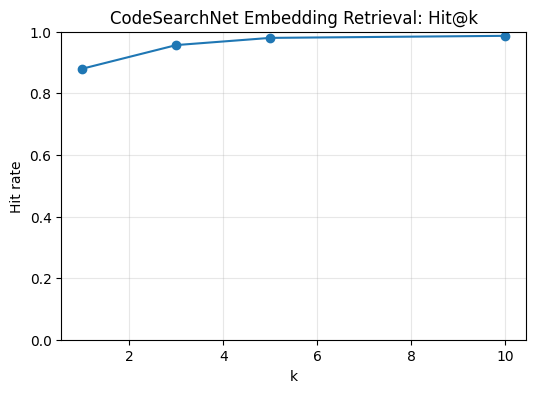

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(list(hit_results.keys()), list(hit_results.values()), marker="o")
plt.title("CodeSearchNet Embedding Retrieval: Hit@k")
plt.xlabel("k")
plt.ylabel("Hit rate")
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.savefig("/kaggle/working/codesearchnet_hit_at_k.png")
plt.show()


## Held-out evaluation set: 55 original questions about the demo repository

Expanded from the previous 50 per the professor's feedback: the cross-file category now asks harder, multi-hop reasoning questions (e.g. "trace the flow from X to Y") with **all** genuinely required files listed in `expected_files` rather than crediting a single relevant file, and the unanswerable category grew from 5 to 10 (MongoDB, AWS, ML, Kubernetes, React, 2FA, GraphQL, Stripe, Redis, push notifications), each checked by hand against the actual cloned repository to confirm no such code exists. These questions were written by hand against the real `flasky` repo (verified below against the actual file paths), not copied from CodeSearchNet, and are used **only** for the final end-to-end evaluation two cells down -- never for building chunks, embeddings, the FAISS index, or the confidence-threshold calibration set above -- so a good score here reflects genuine generalization.

In [22]:
# expected_files is always a LIST. Most questions map to one file; cross-file
# questions genuinely require MULTIPLE files, and are scored with the
# stricter ALL_REQUIRED_FILES_HIT@K metric further down, not just "any one
# file was retrieved."
test_questions = [
    # ---- function-level (10) ----
    {"question": "How does the login function authenticate a user?", "category": "function", "expected_status": "SUPPORTED", "expected_files": ["app/auth/views.py"]},
    {"question": "What happens inside the register function when a new user signs up?", "category": "function", "expected_status": "SUPPORTED", "expected_files": ["app/auth/views.py"]},
    {"question": "How does the password_reset_request function work?", "category": "function", "expected_status": "SUPPORTED", "expected_files": ["app/auth/views.py"]},
    {"question": "What does the edit_profile_admin view function do?", "category": "function", "expected_status": "SUPPORTED", "expected_files": ["app/main/views.py"]},
    {"question": "How does the create_app function set up the Flask application?", "category": "function", "expected_status": "SUPPORTED", "expected_files": ["app/__init__.py"]},
    {"question": "What does the send_email function do?", "category": "function", "expected_status": "SUPPORTED", "expected_files": ["app/email.py"]},
    {"question": "How does the moderate_disable view disable a comment?", "category": "function", "expected_status": "SUPPORTED", "expected_files": ["app/main/views.py"]},
    {"question": "What does the after_request function do in the main blueprint?", "category": "function", "expected_status": "SUPPORTED", "expected_files": ["app/main/views.py"]},
    {"question": "How does the make_shell_context function work?", "category": "function", "expected_status": "SUPPORTED", "expected_files": ["flasky.py"]},
    {"question": "What does the admin_required decorator function do?", "category": "function", "expected_status": "SUPPORTED", "expected_files": ["app/decorators.py"]},

    # ---- class-level (8) ----
    {"question": "What does the User class represent and what does it manage?", "category": "class", "expected_status": "SUPPORTED", "expected_files": ["app/models.py"]},
    {"question": "What is the purpose of the Role class?", "category": "class", "expected_status": "SUPPORTED", "expected_files": ["app/models.py"]},
    {"question": "What fields does the LoginForm class define?", "category": "class", "expected_status": "SUPPORTED", "expected_files": ["app/auth/forms.py"]},
    {"question": "What does the EditProfileAdminForm class allow an administrator to edit?", "category": "class", "expected_status": "SUPPORTED", "expected_files": ["app/main/forms.py"]},
    {"question": "What does the Post class model?", "category": "class", "expected_status": "SUPPORTED", "expected_files": ["app/models.py"]},
    {"question": "What does the Comment class represent?", "category": "class", "expected_status": "SUPPORTED", "expected_files": ["app/models.py"]},
    {"question": "What is the AnonymousUser class used for?", "category": "class", "expected_status": "SUPPORTED", "expected_files": ["app/models.py"]},
    {"question": "What fields does the ChangePasswordForm class contain?", "category": "class", "expected_status": "SUPPORTED", "expected_files": ["app/auth/forms.py"]},

    # ---- file / module-level (8) ----
    {"question": "What is contained in the app/decorators.py module?", "category": "file_module", "expected_status": "SUPPORTED", "expected_files": ["app/decorators.py"]},
    {"question": "What does the app/email.py module handle?", "category": "file_module", "expected_status": "SUPPORTED", "expected_files": ["app/email.py"]},
    {"question": "What is the purpose of config.py in this project?", "category": "file_module", "expected_status": "SUPPORTED", "expected_files": ["config.py"]},
    {"question": "What does app/main/errors.py handle?", "category": "file_module", "expected_status": "SUPPORTED", "expected_files": ["app/main/errors.py"]},
    {"question": "What does the flasky.py script at the project root do?", "category": "file_module", "expected_status": "SUPPORTED", "expected_files": ["flasky.py"]},
    {"question": "What is app/fake.py used for?", "category": "file_module", "expected_status": "SUPPORTED", "expected_files": ["app/fake.py"]},
    {"question": "What does app/exceptions.py define?", "category": "file_module", "expected_status": "SUPPORTED", "expected_files": ["app/exceptions.py"]},
    {"question": "What does app/api/decorators.py provide for the API blueprint?", "category": "file_module", "expected_status": "SUPPORTED", "expected_files": ["app/api/decorators.py"]},

    # ---- configuration (6) ----
    {"question": "How is the database URI configured for the development environment?", "category": "configuration", "expected_status": "SUPPORTED", "expected_files": ["config.py"]},
    {"question": "What environment variables does the configuration read for mail settings?", "category": "configuration", "expected_status": "SUPPORTED", "expected_files": ["config.py"]},
    {"question": "What is different about ProductionConfig compared to the base Config class?", "category": "configuration", "expected_status": "SUPPORTED", "expected_files": ["config.py"]},
    {"question": "How is the app configured for deployment on Heroku?", "category": "configuration", "expected_status": "SUPPORTED", "expected_files": ["config.py"]},
    {"question": "What is the TestingConfig configuration class used for?", "category": "configuration", "expected_status": "SUPPORTED", "expected_files": ["config.py"]},
    {"question": "Which configuration class is used for Docker deployment?", "category": "configuration", "expected_status": "SUPPORTED", "expected_files": ["config.py"]},

    # ---- cross-file reasoning (8) -- multi-hop, all listed files genuinely required ----
    {"question": "Trace the flow from the login route to user authentication.", "category": "cross_file", "expected_status": "SUPPORTED", "expected_files": ["app/auth/views.py", "app/models.py"]},
    {"question": "What happens after a user submits the registration form?", "category": "cross_file", "expected_status": "SUPPORTED", "expected_files": ["app/auth/views.py", "app/models.py", "app/email.py"]},
    {"question": "Which components participate in password reset?", "category": "cross_file", "expected_status": "SUPPORTED", "expected_files": ["app/auth/views.py", "app/models.py", "app/email.py", "app/auth/forms.py"]},
    {"question": "How does the application determine whether a user has permission to perform an operation?", "category": "cross_file", "expected_status": "SUPPORTED", "expected_files": ["app/decorators.py", "app/models.py"]},
    {"question": "Which functions are involved when a blog post is created?", "category": "cross_file", "expected_status": "SUPPORTED", "expected_files": ["app/main/views.py", "app/models.py", "app/main/forms.py"]},
    {"question": "How does information move from the web form to the database when a user edits their profile?", "category": "cross_file", "expected_status": "SUPPORTED", "expected_files": ["app/main/views.py", "app/main/forms.py", "app/models.py"]},
    {"question": "How does creating a new post through the API relate to the Post class's to_json and from_json methods?", "category": "cross_file", "expected_status": "SUPPORTED", "expected_files": ["app/api/posts.py", "app/models.py"]},
    {"question": "How does the create_app factory function wire together the configuration classes from config.py?", "category": "cross_file", "expected_status": "SUPPORTED", "expected_files": ["app/__init__.py", "config.py"]},

    # ---- implementation detail (5) ----
    {"question": "How does the User class store passwords -- are they hashed?", "category": "implementation_detail", "expected_status": "SUPPORTED", "expected_files": ["app/models.py"]},
    {"question": "What library does the User class use to generate confirmation and password-reset tokens?", "category": "implementation_detail", "expected_status": "SUPPORTED", "expected_files": ["app/models.py"]},
    {"question": "What HTTP status code does the API's forbidden error handler return?", "category": "implementation_detail", "expected_status": "SUPPORTED", "expected_files": ["app/api/errors.py"]},
    {"question": "How is the Gravatar hash computed in the User class?", "category": "implementation_detail", "expected_status": "SUPPORTED", "expected_files": ["app/models.py"]},
    {"question": "Does the send_email function send emails synchronously or asynchronously?", "category": "implementation_detail", "expected_status": "SUPPORTED", "expected_files": ["app/email.py"]},

    # ---- unanswerable / out-of-scope (10) -- verified against the cloned repo: none of this exists ----
    {"question": "How does this application connect to MongoDB?", "category": "unanswerable", "expected_status": "INSUFFICIENT_EVIDENCE", "expected_files": []},
    {"question": "What AWS service does the application use for image storage?", "category": "unanswerable", "expected_status": "INSUFFICIENT_EVIDENCE", "expected_files": []},
    {"question": "Which machine learning model performs image classification in this app?", "category": "unanswerable", "expected_status": "INSUFFICIENT_EVIDENCE", "expected_files": []},
    {"question": "How is the application deployed using Kubernetes?", "category": "unanswerable", "expected_status": "INSUFFICIENT_EVIDENCE", "expected_files": []},
    {"question": "What version of React is used for this project's frontend?", "category": "unanswerable", "expected_status": "INSUFFICIENT_EVIDENCE", "expected_files": []},
    {"question": "How does the app implement two-factor authentication (2FA)?", "category": "unanswerable", "expected_status": "INSUFFICIENT_EVIDENCE", "expected_files": []},
    {"question": "What GraphQL schema does this application expose?", "category": "unanswerable", "expected_status": "INSUFFICIENT_EVIDENCE", "expected_files": []},
    {"question": "How does the application integrate with Stripe for payments?", "category": "unanswerable", "expected_status": "INSUFFICIENT_EVIDENCE", "expected_files": []},
    {"question": "What caching layer such as Redis does this application use?", "category": "unanswerable", "expected_status": "INSUFFICIENT_EVIDENCE", "expected_files": []},
    {"question": "How does the application send push notifications to mobile devices?", "category": "unanswerable", "expected_status": "INSUFFICIENT_EVIDENCE", "expected_files": []},
]

from collections import Counter
print("Total questions:", len(test_questions))
print(Counter(q["category"] for q in test_questions))
assert len(test_questions) == 55
assert sum(1 for q in test_questions if q["expected_status"] == "INSUFFICIENT_EVIDENCE") >= 10


Total questions: 55
Counter({'function': 10, 'unanswerable': 10, 'class': 8, 'file_module': 8, 'cross_file': 8, 'configuration': 6, 'implementation_detail': 5})


## Retrieval metrics: Hit@1, Hit@3, Hit@5, MRR, and cross-file breakdowns

- **Hit@k / MRR** -- computed over all SUPPORTED questions using the "any expected file retrieved" rule (an unanswerable question has no "correct file" for retrieval to find, so it's excluded).
- **Any Relevant File Hit@K** -- identical definition, reported separately and restricted to the `cross_file` category only, so it's directly comparable to the stricter metric below.
- **All Required Files Hit@K** -- for `cross_file` questions specifically: did the top-k retrieved files cover **every** file listed in `expected_files`, not just one of them? This is the metric that actually measures whether call-graph expansion is pulling in the full multi-file evidence a hard reasoning question needs, rather than crediting a lucky single-file match.

In [23]:
def retrieval_metrics(questions, retrieve_fn, k=5):
    """Hit@1 / Hit@3 / Hit@5 / MRR against the file-level ground truth,
    restricted to SUPPORTED questions, using the ANY-expected-file-retrieved
    rule (a hit if at least one of a question's expected_files shows up)."""
    ranks = []
    for item in questions:
        if item["expected_status"] != "SUPPORTED":
            continue
        top = retrieve_fn(item["question"], k=max(k, 5))
        retrieved_files = [c["file"] for c, _ in top]
        rank = next((i + 1 for i, f in enumerate(retrieved_files) if f in item["expected_files"]), None)
        ranks.append(rank)

    n = len(ranks)
    hit1 = sum(1 for r in ranks if r is not None and r <= 1) / n
    hit3 = sum(1 for r in ranks if r is not None and r <= 3) / n
    hit5 = sum(1 for r in ranks if r is not None and r <= 5) / n
    mrr = sum((1.0 / r) if r else 0.0 for r in ranks) / n
    return {"Hit@1": hit1, "Hit@3": hit3, "Hit@5": hit5, "MRR": mrr}


def cross_file_retrieval_metrics(questions, retrieve_fn, k=5):
    """ANY_RELEVANT_FILE_HIT@K and ALL_REQUIRED_FILES_HIT@K, restricted to
    the cross_file category. The gap between these two numbers is the most
    direct measurement of what the NetworkX call-graph expansion is
    actually contributing: ANY@K can be high from semantic similarity alone,
    while ALL@K requires the multi-hop evidence gathering to have worked."""
    cross_file_qs = [q for q in questions if q["category"] == "cross_file" and q["expected_status"] == "SUPPORTED"]
    any_hits, all_hits = [], []
    for item in cross_file_qs:
        top = retrieve_fn(item["question"], k=k)
        retrieved_files = set(c["file"] for c, _ in top)
        expected = set(item["expected_files"])
        any_hits.append(bool(retrieved_files & expected))
        all_hits.append(expected.issubset(retrieved_files))
    n = len(cross_file_qs)
    return {
        f"Any Relevant File Hit@{k}": sum(any_hits) / n if n else float("nan"),
        f"All Required Files Hit@{k}": sum(all_hits) / n if n else float("nan"),
    }


## Answer-generation metrics: citation accuracy, citation validity, supported-answer accuracy, abstention accuracy, hallucination rate

- **Citation Accuracy** -- of SUPPORTED-expected questions, the % where the system cited (at least one of) the correct file(s).
- **Citation Validity** -- of questions where the system produced at least one citation, the % where that citation structurally corresponds to evidence the system actually retrieved (regardless of whether it happens to be the *expected* file). This isolates "did the system cite something real" from "did it cite the *right* real thing."
- **Supported Answer Accuracy** (item 3 fix) -- citation correctness alone is not proof the *answer text* itself is grounded: a model could cite the right file and still write an answer that doesn't actually draw on it. This metric checks, for SUPPORTED-expected questions, the % where the system (a) predicted SUPPORTED **and** (b) the answer text is independently judged *grounded* in the retrieved evidence -- via `is_answer_grounded`, a lexical-overlap heuristic that checks whether the answer reuses distinctive identifiers/words that actually appear in the retrieved code/docstrings, filtered against a stoplist of generic programming terms so it isn't trivially satisfied. This is a cheap, repeatable proxy, not a semantic-entailment check -- treat it as a signal for aggregate comparison and spot-checking, not ground truth for any single row.
- **Abstention Accuracy** -- of unanswerable questions, the % where the system correctly returned `INSUFFICIENT_EVIDENCE`.
- **Hallucination Rate** -- of unanswerable questions, the % where the system nevertheless returned `SUPPORTED` with a confident-sounding answer. The baseline (no abstention mechanism at all) should score high here; the proposed system should score near zero -- but per the professor's feedback, this must come from genuinely answering the SUPPORTED questions well too, not from refusing everything.


In [24]:
def answer_generation_metrics(df):
    supported = df[df["expected_status"] == "SUPPORTED"]
    unanswerable = df[df["expected_status"] == "INSUFFICIENT_EVIDENCE"]
    has_citation = df[df["predicted_citation"].notna()]

    citation_accuracy = supported["citation_correct"].mean() if len(supported) else float("nan")
    citation_validity = has_citation["citation_valid"].mean() if len(has_citation) else float("nan")

    # FIX (item 3): this used to be (predicted SUPPORTED) & citation_correct,
    # which only checks that the CITATION points at the right file -- it says
    # nothing about whether the answer TEXT itself is actually grounded in
    # the retrieved evidence. Now driven by the independent `answer_grounded`
    # heuristic column added in the evaluation loop below.
    supported_answer_accuracy = (
        ((supported["predicted_status"] == "SUPPORTED") & (supported["answer_grounded"] == True)).mean()
        if len(supported) else float("nan")
    )
    abstention_accuracy = (
        (unanswerable["predicted_status"] == "INSUFFICIENT_EVIDENCE").mean()
        if len(unanswerable) else float("nan")
    )
    hallucination_rate = (
        (unanswerable["predicted_status"] == "SUPPORTED").mean()
        if len(unanswerable) else float("nan")
    )
    return {
        "Citation Accuracy": citation_accuracy,
        "Citation Validity": citation_validity,
        "Supported Answer Accuracy": supported_answer_accuracy,
        "Abstention Accuracy": abstention_accuracy,
        "Hallucination Rate": hallucination_rate,
    }


## Baseline vs. proposed: full end-to-end run + error analysis

Both pipelines run on the exact same 55 held-out questions. Nothing here changes the test set between systems, hardcodes scores, discards failed questions, or tunes anything after seeing predictions -- whatever numbers come out of this cell are what gets reported. Each row also gets a best-effort, heuristic **error category** (item 17) to speed up manual triage for the viva; see the caveat in `classify_error` below about its limits.

In [25]:
import re
import pandas as pd

# NOTE: _WORD_RE, _GENERIC_CODE_WORDS, and extract_evidence_tokens are now
# defined once, earlier, in the "Grounded generation" section (cell 16) --
# they're shared between the generation-layer citation-inference fallback
# and the evaluation-layer proxies below, so there is exactly one
# definition rather than two that could quietly drift apart.

def is_answer_grounded(answer, context_chunks, min_overlap=2):
    """True if the answer text shares at least `min_overlap` distinctive
    tokens with the retrieved evidence (or with every evidence token, if
    there are fewer than that many available -- e.g. a very short chunk)."""
    if not answer or not context_chunks:
        return False
    evidence_tokens = extract_evidence_tokens(context_chunks)
    if not evidence_tokens:
        return False
    answer_tokens = {w.lower() for w in _WORD_RE.findall(answer)}
    needed = min(min_overlap, len(evidence_tokens))
    return len(evidence_tokens & answer_tokens) >= needed


def _retrieval_hits_for_question(item, retrieve_fn, k_values=(1, 3, 5)):
    """Per-question retrieval hit booleans + whether ALL required files (for
    cross-file questions) were covered within top-5, PLUS the actual
    retrieved chunks (used for the answer-groundedness check below). Used
    both for the CSV columns the professor asked for and for error-category
    classification."""
    if item["expected_status"] != "SUPPORTED":
        return {f"hit_at_{k}": None for k in k_values} | {"all_required_hit": None, "retrieved_chunks": []}
    top = retrieve_fn(item["question"], k=max(k_values))
    retrieved_files = [c["file"] for c, _ in top]
    hits = {f"hit_at_{k}": any(f in item["expected_files"] for f in retrieved_files[:k]) for k in k_values}
    all_required_hit = set(item["expected_files"]).issubset(set(retrieved_files[:max(k_values)]))
    hits["all_required_hit"] = all_required_hit
    hits["retrieved_chunks"] = [c for c, _ in top]
    return hits


def classify_error(row):
    """Best-effort AUTOMATIC error triage (item 9). This is a heuristic over
    metrics we can compute without a human -- it cannot fully distinguish an
    outright LLM generation failure from a subtle parser miss without someone
    reading the raw text, which is exactly what the debug cell earlier in the
    notebook is for. Treat this column as a starting point for manual
    spot-checking, not as ground truth.
    """
    if row["expected_status"] == "INSUFFICIENT_EVIDENCE":
        return "Correct Abstention" if row["predicted_status"] == "INSUFFICIENT_EVIDENCE" else "Hallucination"

    # From here: expected_status == SUPPORTED
    if row["predicted_status"] == "SUPPORTED" and row["citation_correct"] and row.get("answer_grounded"):
        return "Correct Answer"

    if row["hit_at_5"] is False:
        return "Retrieval Failure"
    if row["hit_at_1"] is False and row["hit_at_5"] is True:
        return "Partial Retrieval"
    if row["category"] == "cross_file" and row["all_required_hit"] is False:
        return "Call Graph Failure"
    if row["predicted_status"] == "INSUFFICIENT_EVIDENCE":
        if row["raw_llm_output"] and "STATUS" not in row["raw_llm_output"].upper():
            return "Citation Parsing Failure"
        return "Citation Validation Failure" if row["raw_llm_output"] else "LLM Generation Failure"
    if row["predicted_status"] == "SUPPORTED" and (not row["citation_correct"] or not row.get("answer_grounded")):
        return "LLM Generation Failure"
    return "Other / Unclassified"


def run_end_to_end_eval(questions, answer_fn, retrieve_fn, system_name):
    rows = []
    for item in questions:
        result = answer_fn(item["question"])
        expected_files = item.get("expected_files", [])
        hit_info = _retrieval_hits_for_question(item, retrieve_fn)
        retrieved_chunks = hit_info.pop("retrieved_chunks")

        citation_correct = False
        if item["expected_status"] == "SUPPORTED":
            cited_files = [c.split(":")[0] for c in result["citations"]]
            citation_correct = any(f in expected_files for f in cited_files)

        # FIX (item 3): independent groundedness check on the answer TEXT,
        # separate from citation_correct. Only meaningful for SUPPORTED-
        # expected questions -- for unanswerable ones, correctness is
        # entirely captured by abstention_correct/hallucination below.
        answer_grounded = None
        if item["expected_status"] == "SUPPORTED":
            answer_grounded = is_answer_grounded(result["answer"], retrieved_chunks)

        status_correct = result["status"] == item["expected_status"]
        abstention_correct = (
            item["expected_status"] == "INSUFFICIENT_EVIDENCE" and result["status"] == "INSUFFICIENT_EVIDENCE"
        )
        hallucination = item["expected_status"] == "INSUFFICIENT_EVIDENCE" and result["status"] == "SUPPORTED"
        answer_correct = item["expected_status"] == "SUPPORTED" and status_correct and citation_correct and bool(answer_grounded)

        row = {
            "system": system_name,
            "question": item["question"],
            "category": item["category"],
            "expected_status": item["expected_status"],
            "predicted_status": result["status"],
            "expected_files": ";".join(expected_files) if expected_files else None,
            "predicted_citation": ";".join(result["citations"]) if result["citations"] else None,
            "retrieval_confidence": result["confidence"],
            **hit_info,
            "citation_valid": result["citation_valid"],
            "citation_correct": citation_correct,
            "answer_grounded": answer_grounded,
            "answer_correct": answer_correct,
            "abstention_correct": abstention_correct,
            "hallucination": hallucination,
            "status_correct": status_correct,
            "answer": result["answer"],
            "raw_llm_output": result.get("raw_llm_output"),
        }
        row["error_category"] = classify_error(row)
        rows.append(row)
    return pd.DataFrame(rows)


print("Running NAIVE BASELINE system on 55 held-out questions...")
baseline_df = run_end_to_end_eval(test_questions, answer_question_baseline, semantic_search, "Naive Baseline")

print("Running PROPOSED SYSTEM on 55 held-out questions...")
proposed_df = run_end_to_end_eval(test_questions, answer_question_proposed, hybrid_retrieve, "Proposed System")


Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Running NAIVE BASELINE system on 55 held-out questions...


Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both

Running PROPOSED SYSTEM on 55 held-out questions...


Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both

In [26]:
baseline_retrieval = retrieval_metrics(test_questions, semantic_search)
proposed_retrieval = retrieval_metrics(test_questions, hybrid_retrieve)

baseline_cross = cross_file_retrieval_metrics(test_questions, semantic_search)
proposed_cross = cross_file_retrieval_metrics(test_questions, hybrid_retrieve)

baseline_gen = answer_generation_metrics(baseline_df)
proposed_gen = answer_generation_metrics(proposed_df)

comparison_table = pd.DataFrame([
    {"System": "Naive Baseline", **baseline_retrieval, **baseline_cross, **baseline_gen},
    {"System": "Proposed System", **proposed_retrieval, **proposed_cross, **proposed_gen},
]).set_index("System")

comparison_table


,Hit@1,Hit@3,Hit@5,MRR,Any Relevant File Hit@5,All Required Files Hit@5,Citation Accuracy,Citation Validity,Supported Answer Accuracy,Abstention Accuracy,Hallucination Rate
System,,,,,,,,,,,
Naive Baseline,0.822222,0.977778,0.977778,0.896296,1.0,0.375,0.977778,1.0,0.977778,0.0,1.0
Proposed System,0.933333,0.977778,0.977778,0.955556,1.0,0.625,0.733333,1.0,0.777778,1.0,0.0


In [27]:
combined_df = pd.concat([baseline_df, proposed_df], ignore_index=True)
csv_columns = [
    "question", "category", "expected_status", "predicted_status", "expected_files",
    "predicted_citation", "retrieval_confidence", "hit_at_1", "hit_at_3", "hit_at_5",
    "citation_valid", "citation_correct", "answer_grounded", "answer_correct",
    "abstention_correct", "hallucination", "answer", "error_category", "system",
]
combined_df[csv_columns].to_csv("/kaggle/working/eval_results.csv", index=False)
print(f"Saved {len(combined_df)} rows to /kaggle/working/eval_results.csv")
combined_df[csv_columns].head()


Saved 110 rows to /kaggle/working/eval_results.csv


,question,category,expected_status,predicted_status,expected_files,predicted_citation,retrieval_confidence,hit_at_1,hit_at_3,hit_at_5,citation_valid,citation_correct,answer_grounded,answer_correct,abstention_correct,hallucination,answer,error_category,system
0,How does the login function authenticate a user?,function,SUPPORTED,SUPPORTED,app/auth/views.py,app/auth/views.py:31-42;app/api/authentication...,0.740517,True,True,True,True,True,True,True,False,False,The login function authenticates a user based ...,Correct Answer,Naive Baseline
1,What happens inside the register function when...,function,SUPPORTED,SUPPORTED,app/auth/views.py,app/auth/views.py:54-67;app/auth/views.py:31-4...,0.604099,True,True,True,True,True,True,True,False,False,When a new user signs up through the `register...,Correct Answer,Naive Baseline
2,How does the password_reset_request function w...,function,SUPPORTED,SUPPORTED,app/auth/views.py,app/auth/views.py:110-124;app/auth/views.py:12...,0.772299,True,True,True,True,True,True,True,False,False,The `password_reset_request` function handles ...,Correct Answer,Naive Baseline
3,What does the edit_profile_admin view function...,function,SUPPORTED,SUPPORTED,app/main/views.py,app/main/views.py:93-115;app/main/views.py:74-...,0.806084,True,True,True,True,True,True,True,False,False,The `edit_profile_admin` view function updates...,Correct Answer,Naive Baseline
4,How does the create_app function set up the Fl...,function,SUPPORTED,SUPPORTED,app/__init__.py,app/__init__.py:20-45;config.py:108-116;config...,0.805259,True,True,True,True,True,True,True,False,False,The `create_app` function sets up the Flask ap...,Correct Answer,Naive Baseline


## Error category summary

A quick triage view (item 9): how many questions in each system fall into each automatically-detected failure category (Retrieval Failure, Partial Retrieval, Call Graph Failure, LLM Generation Failure, Citation Parsing Failure, Citation Validation Failure, Hallucination, Correct Abstention -- plus Correct Answer / Other for rows that don't fall into a failure bucket). Use this to decide which raw LLM outputs are worth reading manually before the viva.


In [28]:
error_summary = combined_df.groupby(["system", "error_category"]).size().unstack(fill_value=0)
error_summary


error_category,Citation Parsing Failure,Citation Validation Failure,Correct Abstention,Correct Answer,Hallucination,LLM Generation Failure,Retrieval Failure
system,,,,,,,
Naive Baseline,0,0,0,43,10,1,1
Proposed System,4,5,10,33,0,2,1


### Diagnostic: remaining "Citation Parsing Failure" rows

Before the citation-inference fallback, 18 of 55 questions landed in this bucket: the model answered correctly in plain prose but never wrote STATUS/CITATIONS/ANSWER. After the fallback, rows should only remain here if the raw output was too short, read like a refusal, or overlapped no retrieved chunk. Read a few raw outputs below to see which case applies.


In [29]:
pf_rows = proposed_df[proposed_df["error_category"] == "Citation Parsing Failure"]
print(f"{len(pf_rows)} questions still in Citation Parsing Failure.")
if len(pf_rows):
    print(pf_rows["category"].value_counts())
    for _, row in pf_rows.head(5).iterrows():
        print("=" * 90)
        print(f"[{row['category']}] {row['question']}  (confidence {row['retrieval_confidence']:.3f})")
        print(repr(row["raw_llm_output"]))

# Safety check on the fallback: unanswerable questions must NOT be rescued into SUPPORTED.
unans = proposed_df[proposed_df["expected_status"] == "INSUFFICIENT_EVIDENCE"]
print(f"\nUnanswerable questions predicted SUPPORTED (hallucinations): {(unans['predicted_status'] == 'SUPPORTED').sum()}/{len(unans)}")


4 questions still in Citation Parsing Failure.
category
file_module              3
implementation_detail    1
Name: count, dtype: int64
[file_module] What is the purpose of config.py in this project?  (confidence 0.765)
'The repository does not contain sufficient evidence to answer this question.'
[file_module] What does app/main/errors.py handle?  (confidence 0.901)
'The repository does not contain sufficient evidence to answer this question.'
[file_module] What is app/fake.py used for?  (confidence 0.831)
'The repository does not contain sufficient evidence to answer this question.'
[implementation_detail] What library does the User class use to generate confirmation and password-reset tokens?  (confidence 0.761)
'The repository does not contain sufficient evidence to answer this question.'

Unanswerable questions predicted SUPPORTED (hallucinations): 0/10


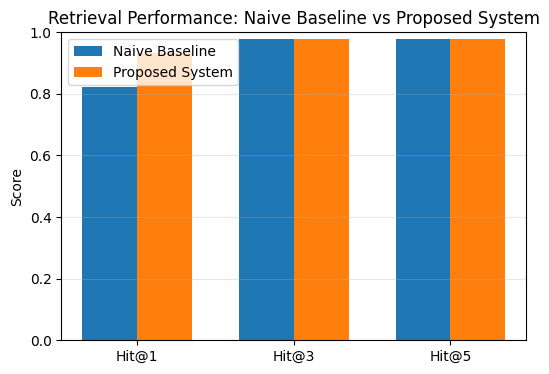

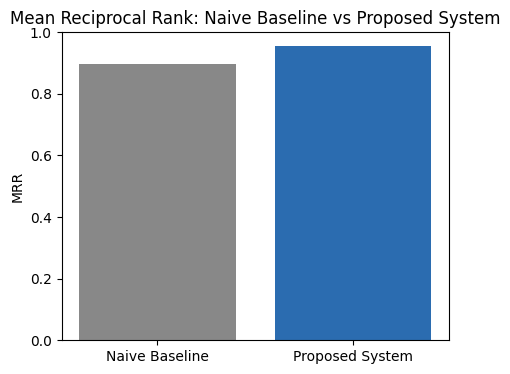

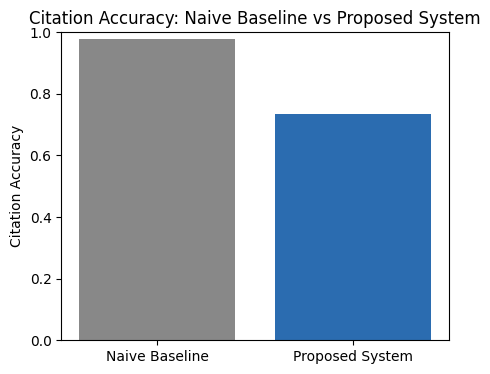

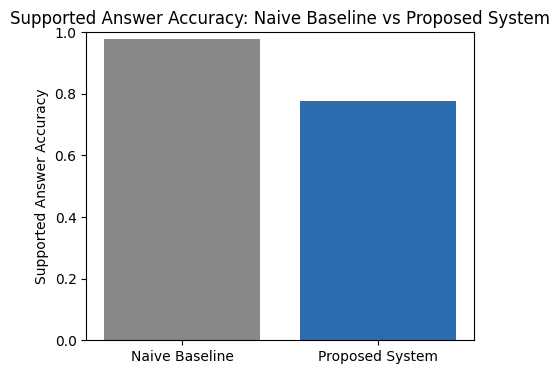

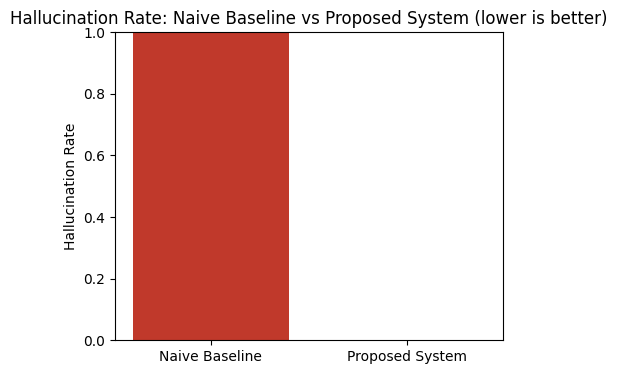

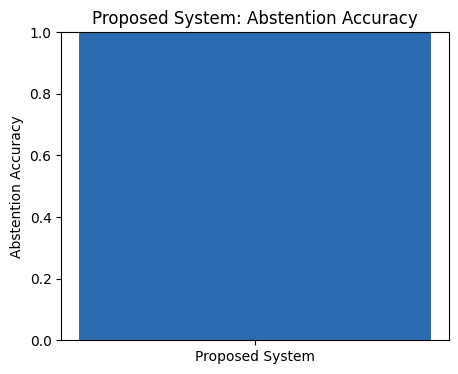

In [30]:
import numpy as np

# Plot 1: Hit@1/3/5, baseline vs proposed
metrics_labels = ["Hit@1", "Hit@3", "Hit@5"]
x = np.arange(len(metrics_labels))
width = 0.35
plt.figure(figsize=(6, 4))
plt.bar(x - width/2, [baseline_retrieval[m] for m in metrics_labels], width, label="Naive Baseline")
plt.bar(x + width/2, [proposed_retrieval[m] for m in metrics_labels], width, label="Proposed System")
plt.xticks(x, metrics_labels)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Retrieval Performance: Naive Baseline vs Proposed System")
plt.legend()
plt.grid(True, alpha=0.3, axis="y")
plt.savefig("/kaggle/working/retrieval_hit_at_k.png")
plt.show()

# Plot 2: MRR
plt.figure(figsize=(5, 4))
plt.bar(["Naive Baseline", "Proposed System"], [baseline_retrieval["MRR"], proposed_retrieval["MRR"]],
        color=["#888888", "#2b6cb0"])
plt.ylim(0, 1)
plt.ylabel("MRR")
plt.title("Mean Reciprocal Rank: Naive Baseline vs Proposed System")
plt.savefig("/kaggle/working/mrr_comparison.png")
plt.show()

# Plot 3: Citation accuracy
plt.figure(figsize=(5, 4))
plt.bar(["Naive Baseline", "Proposed System"], [baseline_gen["Citation Accuracy"], proposed_gen["Citation Accuracy"]],
        color=["#888888", "#2b6cb0"])
plt.ylim(0, 1)
plt.ylabel("Citation Accuracy")
plt.title("Citation Accuracy: Naive Baseline vs Proposed System")
plt.savefig("/kaggle/working/citation_accuracy_comparison.png")
plt.show()

# Plot 4: Supported Answer Accuracy
plt.figure(figsize=(5, 4))
plt.bar(["Naive Baseline", "Proposed System"], [baseline_gen["Supported Answer Accuracy"], proposed_gen["Supported Answer Accuracy"]],
        color=["#888888", "#2b6cb0"])
plt.ylim(0, 1)
plt.ylabel("Supported Answer Accuracy")
plt.title("Supported Answer Accuracy: Naive Baseline vs Proposed System")
plt.savefig("/kaggle/working/supported_answer_accuracy_comparison.png")
plt.show()

# Plot 5: Hallucination rate (lower is better)
plt.figure(figsize=(5, 4))
plt.bar(["Naive Baseline", "Proposed System"], [baseline_gen["Hallucination Rate"], proposed_gen["Hallucination Rate"]],
        color=["#c0392b", "#2b6cb0"])
plt.ylim(0, 1)
plt.ylabel("Hallucination Rate")
plt.title("Hallucination Rate: Naive Baseline vs Proposed System (lower is better)")
plt.savefig("/kaggle/working/hallucination_rate_comparison.png")
plt.show()

# Plot 6: Proposed System abstention accuracy (the naive baseline has no
# abstention mechanism at all, so it is not a meaningful comparison point
# here -- shown alone per the professor's spec)
plt.figure(figsize=(5, 4))
plt.bar(["Proposed System"], [proposed_gen["Abstention Accuracy"]], color=["#2b6cb0"])
plt.ylim(0, 1)
plt.ylabel("Abstention Accuracy")
plt.title("Proposed System: Abstention Accuracy")
plt.savefig("/kaggle/working/abstention_accuracy.png")
plt.show()


## Final results

All numbers below come directly from `comparison_table` computed two cells up -- nothing here is hardcoded or adjusted after the fact.

In [31]:
def _fmt(x):
    return f"{x:.2f}" if isinstance(x, float) and not pd.isna(x) else "N/A"

print("=" * 40)
print("FINAL EVALUATION")
print("=" * 40)

for label, retrieval, cross, gen in [
    ("NAIVE BASELINE", baseline_retrieval, baseline_cross, baseline_gen),
    ("PROPOSED SYSTEM", proposed_retrieval, proposed_cross, proposed_gen),
]:
    print(f"\n{label}")
    print(f"Hit@1: {_fmt(retrieval['Hit@1'])}")
    print(f"Hit@3: {_fmt(retrieval['Hit@3'])}")
    print(f"Hit@5: {_fmt(retrieval['Hit@5'])}")
    print(f"MRR: {_fmt(retrieval['MRR'])}")
    for k, v in cross.items():
        print(f"{k}: {_fmt(v)}")
    print(f"Supported Answer Accuracy: {_fmt(gen['Supported Answer Accuracy'])}")
    print(f"Citation Accuracy: {_fmt(gen['Citation Accuracy'])}")
    print(f"Citation Validity: {_fmt(gen['Citation Validity'])}")
    print(f"Abstention Accuracy: {_fmt(gen['Abstention Accuracy'])}")
    print(f"Hallucination Rate: {_fmt(gen['Hallucination Rate'])}")

print("\n" + "=" * 40)


FINAL EVALUATION

NAIVE BASELINE
Hit@1: 0.82
Hit@3: 0.98
Hit@5: 0.98
MRR: 0.90
Any Relevant File Hit@5: 1.00
All Required Files Hit@5: 0.38
Supported Answer Accuracy: 0.98
Citation Accuracy: 0.98
Citation Validity: 1.00
Abstention Accuracy: 0.00
Hallucination Rate: 1.00

PROPOSED SYSTEM
Hit@1: 0.93
Hit@3: 0.98
Hit@5: 0.98
MRR: 0.96
Any Relevant File Hit@5: 1.00
All Required Files Hit@5: 0.62
Supported Answer Accuracy: 0.78
Citation Accuracy: 0.73
Citation Validity: 1.00
Abstention Accuracy: 1.00
Hallucination Rate: 0.00



## Demonstration questions

Five questions spanning a simple lookup, a cross-file question, a hard reasoning question, a genuinely unanswerable question, and a completely unrelated question -- for use in the project demo/viva. Each prints the full pipeline trace: retrieved evidence, confidence, final status, answer, citations, and whether citation validation passed.

In [32]:
DEMO_QUESTIONS = [
    ("A. Simple supported question", "What does the send_email function do?"),
    ("B. Cross-file question", "Trace the flow from the login route to user authentication."),
    ("C. Difficult reasoning question", "How does the application determine whether a user has permission to perform an operation?"),
    ("D. Unanswerable question", "How does this application connect to MongoDB?"),
    ("E. Completely unrelated question", "What is the capital of France?"),
]

for label, q in DEMO_QUESTIONS:
    print("=" * 90)
    print(label)
    print("QUESTION:", q)
    result = answer_question_proposed(q)
    print(f"RETRIEVED EVIDENCE: {result['retrieved_files']}")
    print(f"CONFIDENCE: {result['confidence']:.3f}")
    print(f"STATUS: {result['status']}")
    print(f"ANSWER: {result['answer']}")
    print(f"CITATIONS: {result['citations']}")
    print(f"VALIDATION RESULT: {'PASSED' if result['citation_valid'] else 'N/A or FAILED'}")
    print()


Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


A. Simple supported question
QUESTION: What does the send_email function do?


Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


RETRIEVED EVIDENCE: ['app/email.py', 'app/models.py', 'app/main/forms.py', 'app/auth/views.py', 'app/auth/forms.py']
CONFIDENCE: 0.883
STATUS: SUPPORTED
ANSWER: The send_email function sends an email using Flask-Mail with the provided recipient's details, HTML and text templates, and keyword arguments. It creates a new `Message` object, sets its properties including the sender, recipient, subject, body, and HTML content based on the given template and keyword arguments. The message is then sent asynchronously via a thread.
CITATIONS: ['app/email.py:12-20']
VALIDATION RESULT: PASSED

B. Cross-file question
QUESTION: Trace the flow from the login route to user authentication.


Both `max_new_tokens` (=300) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


RETRIEVED EVIDENCE: ['app/auth/views.py', 'app/api/authentication.py', 'app/auth/forms.py', 'app/main/views.py', 'app/models.py']
CONFIDENCE: 0.827
STATUS: SUPPORTED
ANSWER: The flow of the login route to user authentication can be traced through these steps:

1. The login function is called when a user attempts to log in.
2. It initializes a LoginForm object with default values for email and password.
3. If the form is valid, it queries the database for a user matching the provided email address.
4. If the user exists and their password matches the inputted one, it logs the user in using login_user.
5. It sets the remember_me flag based on whether the user wants to stay logged in after logging out.
6. It redirects the user to the specified next URL or the homepage (url_for('main.index')) if next is not set or doesn't start with /.
7. After successful login, the current_user variable is updated to point to the authenticated user.
8. The verify_password function checks if the provided t